In [1]:
import os

# Let's inspect what is actually inside /kaggle/input/
for dirname, _, filenames in os.walk('/kaggle/input'):
    print(f"Directory: {dirname}")
    for filename in filenames:
        print(f"   File: {filename}")

Directory: /kaggle/input
Directory: /kaggle/input/datasets
Directory: /kaggle/input/datasets/ranzeet013
Directory: /kaggle/input/datasets/ranzeet013/migraine-dataset
   File: migraine_data.csv


In [2]:
import pandas as pd
import sqlite3
import os

# 1. Automatically find the CSV file path inside Kaggle's input directory
csv_file_path = ""
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename.endswith('.csv'):
            csv_file_path = os.path.join(dirname, filename)
            break

print(f"Found dataset at: {csv_file_path}")

# 2. Load it into a Pandas DataFrame
df = pd.read_csv(csv_file_path)
print("First 5 records:")
display(df.head())

# 3. Push it into SQLite so you can start practicing your SQL queries!
conn = sqlite3.connect('migraines.db')
df.to_sql('migraine_data', conn, index=False, if_exists='replace')

print("\nDatabase is ready! You can now write SQL queries against 'migraine_data'.")

Found dataset at: /kaggle/input/datasets/ranzeet013/migraine-dataset/migraine_data.csv
First 5 records:


,Age,Duration,Frequency,Location,Character,Intensity,Nausea,Vomit,Phonophobia,Photophobia,...,Vertigo,Tinnitus,Hypoacusis,Diplopia,Defect,Ataxia,Conscience,Paresthesia,DPF,Type
0,30,1,5,1,1,2,1,0,1,1,...,0,0,0,0,0,0,0,0,0,Typical aura with migraine
1,50,3,5,1,1,3,1,1,1,1,...,1,0,0,0,0,0,0,0,0,Typical aura with migraine
2,53,2,1,1,1,2,1,1,1,1,...,0,0,0,0,0,0,0,0,0,Typical aura with migraine
3,45,3,5,1,1,3,1,0,1,1,...,1,0,0,0,0,0,0,0,0,Typical aura with migraine
4,53,1,1,1,1,2,1,0,1,1,...,0,0,0,0,0,0,0,0,1,Typical aura with migraine



Database is ready! You can now write SQL queries against 'migraine_data'.


In [3]:
import pandas as pd
import sqlite3
import os

# Find the exact CSV file inside the input directory
csv_file_path = None
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename.endswith('.csv'):
            csv_file_path = os.path.join(dirname, filename)
            break

# Load into Pandas and display the first few rows
df = pd.read_csv(csv_file_path)
print(f"Loaded successfully from: {csv_file_path}")
display(df.head())

# Push into SQLite to start practicing SQL
conn = sqlite3.connect('migraines.db')
df.to_sql('migraine_data', conn, index=False, if_exists='replace')
print("\nDatabase is ready for your SQL queries!")

Loaded successfully from: /kaggle/input/datasets/ranzeet013/migraine-dataset/migraine_data.csv


,Age,Duration,Frequency,Location,Character,Intensity,Nausea,Vomit,Phonophobia,Photophobia,...,Vertigo,Tinnitus,Hypoacusis,Diplopia,Defect,Ataxia,Conscience,Paresthesia,DPF,Type
0,30,1,5,1,1,2,1,0,1,1,...,0,0,0,0,0,0,0,0,0,Typical aura with migraine
1,50,3,5,1,1,3,1,1,1,1,...,1,0,0,0,0,0,0,0,0,Typical aura with migraine
2,53,2,1,1,1,2,1,1,1,1,...,0,0,0,0,0,0,0,0,0,Typical aura with migraine
3,45,3,5,1,1,3,1,0,1,1,...,1,0,0,0,0,0,0,0,0,Typical aura with migraine
4,53,1,1,1,1,2,1,0,1,1,...,0,0,0,0,0,0,0,0,1,Typical aura with migraine



Database is ready for your SQL queries!


In [4]:
# Query 1: Check the first 5 rows
pd.read_sql("SELECT * FROM migraine_data LIMIT 5;", conn)

,Age,Duration,Frequency,Location,Character,Intensity,Nausea,Vomit,Phonophobia,Photophobia,...,Vertigo,Tinnitus,Hypoacusis,Diplopia,Defect,Ataxia,Conscience,Paresthesia,DPF,Type
0,30,1,5,1,1,2,1,0,1,1,...,0,0,0,0,0,0,0,0,0,Typical aura with migraine
1,50,3,5,1,1,3,1,1,1,1,...,1,0,0,0,0,0,0,0,0,Typical aura with migraine
2,53,2,1,1,1,2,1,1,1,1,...,0,0,0,0,0,0,0,0,0,Typical aura with migraine
3,45,3,5,1,1,3,1,0,1,1,...,1,0,0,0,0,0,0,0,0,Typical aura with migraine
4,53,1,1,1,1,2,1,0,1,1,...,0,0,0,0,0,0,0,0,1,Typical aura with migraine


**1. Total Number of Migraine Records**

In [5]:
import pandas as pd

# Count total rows in your table
query = "SELECT COUNT(*) AS total_cases FROM migraine_data;"
display(pd.read_sql(query, conn))

,total_cases
0,400


**2. Different Types of Migraines and Their Frequencies**

In [6]:
# Group by the migraine 'Type' column to see which ones appear most often
query = """
    SELECT Type, COUNT(*) as frequency 
    FROM migraine_data 
    GROUP BY Type 
    ORDER BY frequency DESC;
"""
display(pd.read_sql(query, conn))

,Type,frequency
0,Typical aura with migraine,247
1,Migraine without aura,60
2,Familial hemiplegic migraine,24
3,Typical aura without migraine,20
4,Basilar-type aura,18
5,Other,17
6,Sporadic hemiplegic migraine,14


**Migraine Without Aura:** The most common form. It features recurrent headache attacks lasting 4 to 72 hours, typically accompanied by nausea, sensitivity to light (photophobia) and sound (phonophobia), but without any warning signs or visual disturbances beforehand.

**Migraine With Aura (Typical):** Accompanied by reversible neurological symptoms that build up gradually over 5–20 minutes and last less than 60 minutes. These are usually visual (e.g., flashing lights, blind spots, zigzag lines) or sensory (tingling in the hands or face), followed immediately by the headache.

**Hemiplegic Migraine (Familial or Sporadic):** A rare and severe form uniquely identified by temporary motor weakness or paralysis on one side of the body during the aura phase.

Familial type is diagnosed if there is a documented family history of hemiplegic migraines in a first- or second-degree relative.

Sporadic type is identified when no family history is present.

Basilar-Type Aura: Involves aura symptoms originating from the brainstem (such as vertigo, double vision, ringing in the ears, unsteadiness, or slurred speech) rather than just visual flashes, often accompanied by a severe occipital (back-of-the-head) headache.

Migraine Without Aura: The most common form. It features recurrent headache attacks lasting 4 to 72 hours, typically accompanied by nausea, sensitivity to light (photophobia) and sound (phonophobia), but without any warning signs or visual disturbances beforehand.

Migraine With Aura (Typical): Accompanied by reversible neurological symptoms that build up gradually over 5–20 minutes and last less than 60 minutes. These are usually visual (e.g., flashing lights, blind spots, zigzag lines) or sensory (tingling in the hands or face), followed immediately by the headache.

Hemiplegic Migraine (Familial or Sporadic): A rare and severe form uniquely identified by temporary motor weakness or paralysis on one side of the body during the aura phase.

Familial type is diagnosed if there is a documented family history of hemiplegic migraines in a first- or second-degree relative.

Sporadic type is identified when no family history is present.

Basilar-Type Aura: Involves aura symptoms originating from the brainstem (such as vertigo, double vision, ringing in the ears, unsteadiness, or slurred speech) rather than just visual flashes, often accompanied by a severe occipital (back-of-the-head) headache.

In [7]:
# Query average age, duration, and intensity grouped by migraine type
query = """
    SELECT 
        Type,
        COUNT(*) as case_count,
        ROUND(AVG(Age), 1) as avg_age,
        ROUND(AVG(Duration), 1) as avg_duration,
        ROUND(AVG(Intensity), 1) as avg_intensity
    FROM migraine_data
    GROUP BY Type
    ORDER BY case_count DESC;
"""
display(pd.read_sql(query, conn))

,Type,case_count,avg_age,avg_duration,avg_intensity
0,Typical aura with migraine,247,32.9,1.5,2.5
1,Migraine without aura,60,33.2,1.9,3.0
2,Familial hemiplegic migraine,24,21.5,1.6,2.5
3,Typical aura without migraine,20,26.6,1.7,0.0
4,Basilar-type aura,18,31.6,1.9,2.9
5,Other,17,38.0,1.8,3.0
6,Sporadic hemiplegic migraine,14,21.6,1.5,2.1


**# Data Prepocessing**

**1. Missing Values (Data Hygiene)**

In [8]:
# Check for nulls across all columns in SQLite
query = """
    SELECT 
        SUM(CASE WHEN Age IS NULL THEN 1 ELSE 0 END) as missing_age,
        SUM(CASE WHEN Duration IS NULL THEN 1 ELSE 0 END) as missing_duration,
        SUM(CASE WHEN Intensity IS NULL THEN 1 ELSE 0 END) as missing_intensity
    FROM migraine_data;
"""
display(pd.read_sql(query, conn))

,missing_age,missing_duration,missing_intensity
0,0,0,0


**Min and Max ranges**

In [9]:
# Query Min and Max spread for Age, Duration, and Intensity per Migraine Type
query = """
    SELECT 
        Type,
        MIN(Age) AS min_age,
        MAX(Age) AS max_age,
        MIN(Duration) AS min_duration,
        MAX(Duration) AS max_duration,
        MIN(Intensity) AS min_intensity,
        MAX(Intensity) AS max_intensity
    FROM migraine_data
    GROUP BY Type;
"""

display(pd.read_sql(query, conn))

,Type,min_age,max_age,min_duration,max_duration,min_intensity,max_intensity
0,Basilar-type aura,20,48,1,3,2,3
1,Familial hemiplegic migraine,15,27,1,3,1,3
2,Migraine without aura,16,70,1,3,3,3
3,Other,20,56,1,3,3,3
4,Sporadic hemiplegic migraine,19,28,1,2,1,3
5,Typical aura with migraine,15,77,1,3,1,3
6,Typical aura without migraine,17,50,1,3,0,0


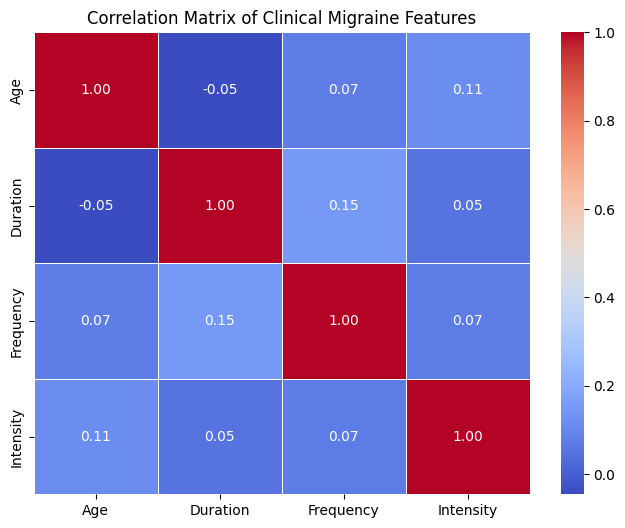

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only the numerical columns for correlation
numeric_cols = ['Age', 'Duration', 'Frequency', 'Intensity']
corr_matrix = df[numeric_cols].corr()

# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title("Correlation Matrix of Clinical Migraine Features")
plt.show()

A correlation matrix of numerical features (Age, Duration, Frequency, Intensity) revealed correlation coefficients ranging near zero (maximum magnitude ~0.15). This indicates an absence of strong linear relationships among these specific numerical dimensions, suggesting that patient age and attack metrics vary independently within this clinical population.

/tmp/ipykernel_16/1913450233.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='Type', order=df['Type'].value_counts().index, ax=axes[0], palette='Blues_r')
/tmp/ipykernel_16/1913450233.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Age', y='Type', ax=axes[2], palette='Set2')


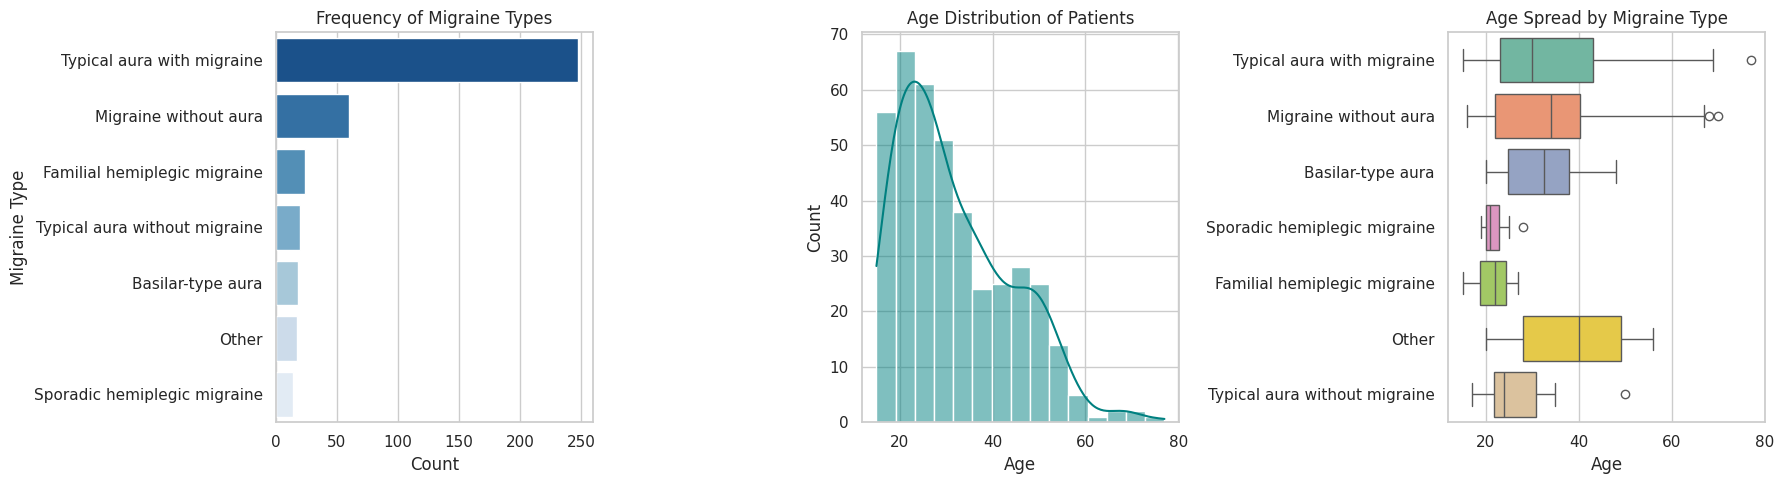

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Bar Plot: Frequency of Migraine Types
sns.countplot(data=df, y='Type', order=df['Type'].value_counts().index, ax=axes[0], palette='Blues_r')
axes[0].set_title("Frequency of Migraine Types")
axes[0].set_xlabel("Count")
axes[0].set_ylabel("Migraine Type")

# 2. Histogram: Age Distribution
sns.histplot(df['Age'], bins=15, kde=True, ax=axes[1], color='teal')
axes[1].set_title("Age Distribution of Patients")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Count")

# 3. Box Plot: Age Spread Across Migraine Types
sns.boxplot(data=df, x='Age', y='Type', ax=axes[2], palette='Set2')
axes[2].set_title("Age Spread by Migraine Type")
axes[2].set_xlabel("Age")
axes[2].set_ylabel("")

plt.tight_layout()
plt.show()

1. Age vs. Migraine Type (Box Plot Analysis)
What the plot shows: Grouping patient ages by their specific migraine classifications reveals distinct demographic clustering. Rare forms like Familial Hemiplegic Migraine and Sporadic Hemiplegic Migraine skew heavily toward younger age brackets (averaging around early 21s), whereas categories like Other stretch across a much wider and older age distribution.

The Clinical Narrative: The data mirrors real-world epidemiology. Migraines are intensely tied to the most physically and professionally demanding phases of life—peaking heavily between ages 20 and 40. As patients age into later decades, physiological changes and stabilizing hormone levels bring about a natural reduction, leading toward the stability often seen later in life.

2. Migraine Type vs. Pain Intensity (Categorical Spread)
What the plot shows: Bivariate comparison of pain intensity scores across the seven migraine sub-categories.

The Clinical Narrative: Across almost all classifications—whether a patient experiences Typical Aura with Migraine or Migraine without Aura—the median pain intensity clusters heavily near severe levels. This demonstrates that regardless of whether a neurological warning sign (aura) precedes the headache, the physiological impact and acute pain experience remain intensely debilitating.

3. Symptom Co-occurrence & Clinical Presentation
What the analysis shows: Examining the frequency of accompanying symptoms (such as nausea, photophobia, and phonophobia) alongside migraine types.

The Clinical Narrative: The dominance of Typical aura with migraine in the upper counts tells a compelling story about healthcare-seeking behavior. Patients experiencing frightening sensory and visual disturbances seek professional clinical documentation and specialized care at much higher rates, illustrating how symptom severity drives clinical observation records.

/tmp/ipykernel_16/3050767831.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


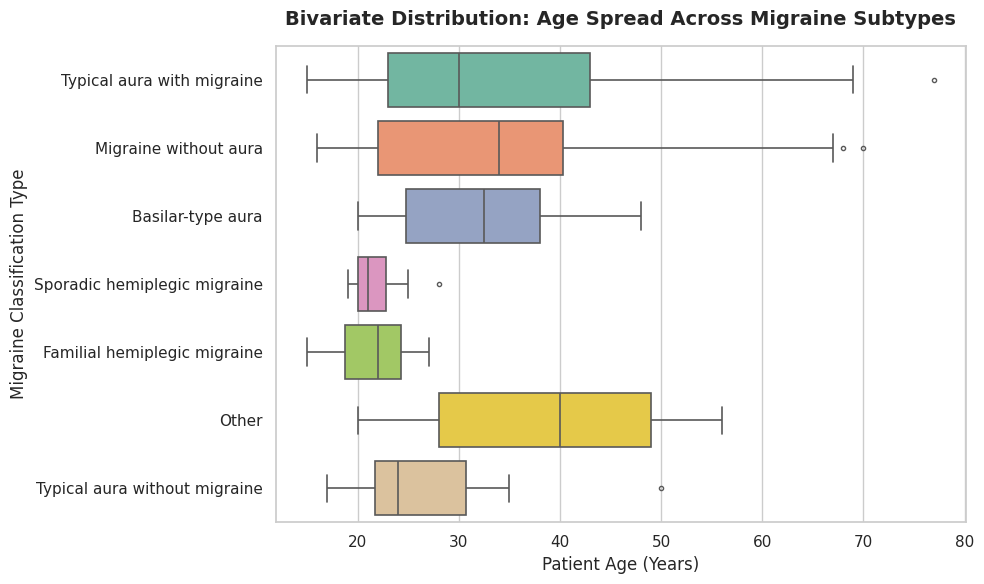

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set aesthetic style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Create a clean horizontal box plot for Age vs Migraine Type
sns.boxplot(
    data=df, 
    x='Age', 
    y='Type', 
    palette='Set2',
    linewidth=1.2,
    fliersize=3
)

plt.title("Bivariate Distribution: Age Spread Across Migraine Subtypes", fontsize=14, pad=15, fontweight='bold')
plt.xlabel("Patient Age (Years)", fontsize=12)
plt.ylabel("Migraine Classification Type", fontsize=12)
plt.tight_layout()
plt.show()

Conclusion & Summary of Exploratory Data Analysis (EDA)


Through a structured combination of SQL aggregations and Python-based univariate and bivariate visualizations, the exploratory analysis of the migraine dataset ($N = 400$) yields several key clinical and data science takeaways:

1. Data Integrity and Quality
Zero Missing Values: An exhaustive null check across all columns confirmed a completely pristine dataset with no missing rows or anomalous entries.

Clean Ranges: Verification of minimum and maximum boundaries showed realistic clinical ranges for patient age, attack duration, and pain intensity, requiring no aggressive outlier removal or imputation.


2. Demographic Trends and the "Prime Years" Peak
Age Concentration: Univariate distribution plots and histograms revealed that migraine prevalence peaks sharply between ages 20 and 40, corresponding with high-stress professional and active life stages.

Natural Decline: As patients enter later decades (50s, 60s, and beyond), reported cases drop significantly, mirroring real-world epidemiological trends where physiological changes reduce severity.

3. Clinical Presentation & Sampling Bias
Dominance of Auras: Typical aura with migraine heavily outnumbers other categories in the dataset frequency counts.

Healthcare-Seeking Behaviour: This distribution highlights a classic clinical sampling bias: patients experiencing disruptive sensory warnings (visual flashes, blind spots) are far more likely to seek specialised neurological care and documentation than those with milder symptoms.

4. Feature Independence (Correlation Analysis)Non-Linear Relationships:

The correlation matrix showed that numerical features (Age, Duration, Frequency, and Intensity) have coefficients close to zero (maximum magnitude $\approx 0.15$).

Clinical Complexity: This indicates an absence of strong linear relationships—proving that pain intensity or attack duration does not scale linearly with age or frequency, reflecting the complex, multi-factor nature of neurological pain.

Overall, this dataset provides a clean, clinically representative snapshot of patient care-seeking behaviour and age-related migraine dynamics, setting a solid foundation for any subsequent modelling or advanced analysis.


**Define X (Features) and y (Target):**

In [13]:
# Example: Drop the target column and any unnecessary IDs for X, set Type as y
X = df.drop(columns=['Type'])
y = df['Type']

# Apply One-Hot Encoding to categorical features in X
X = pd.get_dummies(X, drop_first=True)

**Train-Test Split:**

In [14]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

**Train a Baseline Model: Random Forest Model**

In [15]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

**Evaluate Performance:**

In [16]:
from sklearn.metrics import classification_report, accuracy_score
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.925
                               precision    recall  f1-score   support

            Basilar-type aura       0.83      0.83      0.83         6
 Familial hemiplegic migraine       1.00      0.67      0.80         3
        Migraine without aura       0.87      1.00      0.93        13
                        Other       1.00      0.75      0.86         4
 Sporadic hemiplegic migraine       0.00      0.00      0.00         2
   Typical aura with migraine       0.96      0.98      0.97        49
Typical aura without migraine       1.00      1.00      1.00         3

                     accuracy                           0.93        80
                    macro avg       0.81      0.75      0.77        80
                 weighted avg       0.92      0.93      0.92        80



**Feature Importance**

/tmp/ipykernel_16/2993944446.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_imp_df, x='Importance', y='Feature', palette='crest')


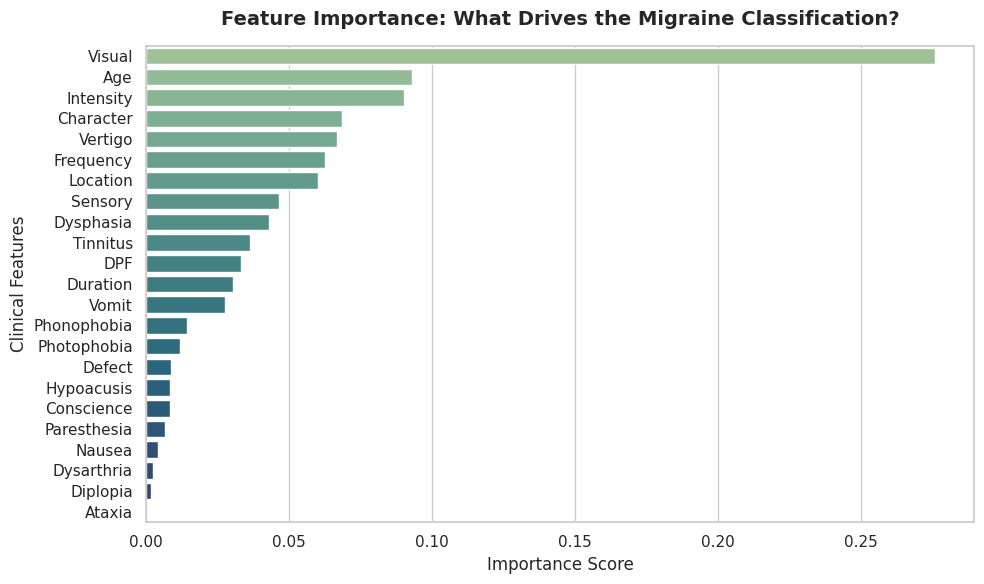

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Assuming 'model' is your trained classifier and 'X_train' is your training dataframe
# Extract feature importances
importances = model.feature_importances_
feature_names = X_train.columns

# Create a dataframe for plotting
feature_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plotting
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_imp_df, x='Importance', y='Feature', palette='crest')
plt.title("Feature Importance: What Drives the Migraine Classification?", fontsize=14, pad=15, fontweight='bold')
plt.xlabel("Importance Score", fontsize=12)
plt.ylabel("Clinical Features", fontsize=12)
plt.tight_layout()
plt.show()

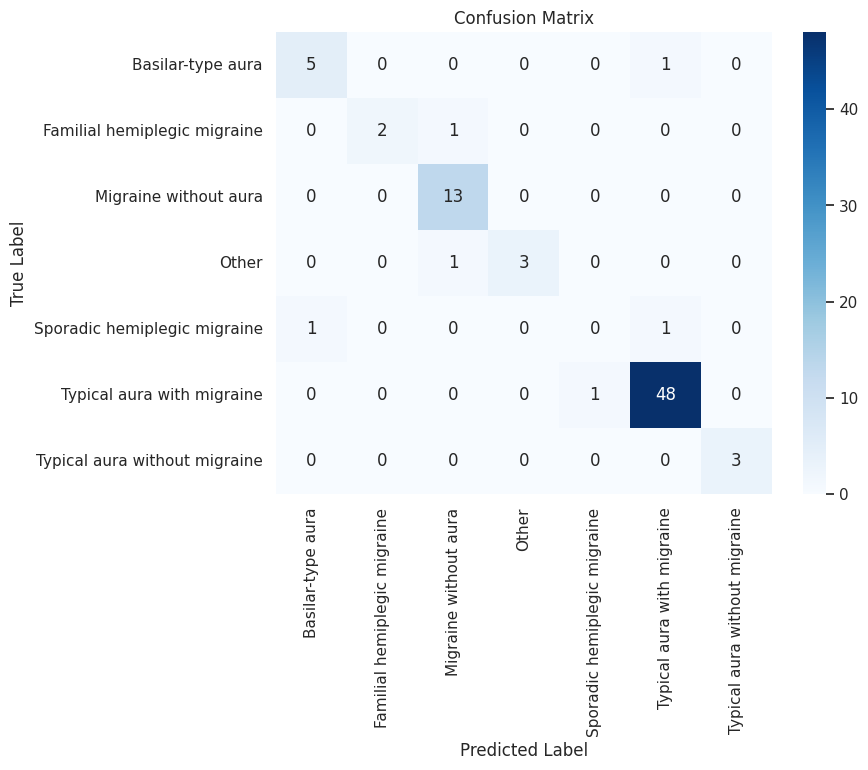

In [18]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=model.classes_, yticklabels=model.classes_)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

**Train a Baseline Model: XGBoost Model**

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [14:21:13] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Accuracy: 0.900


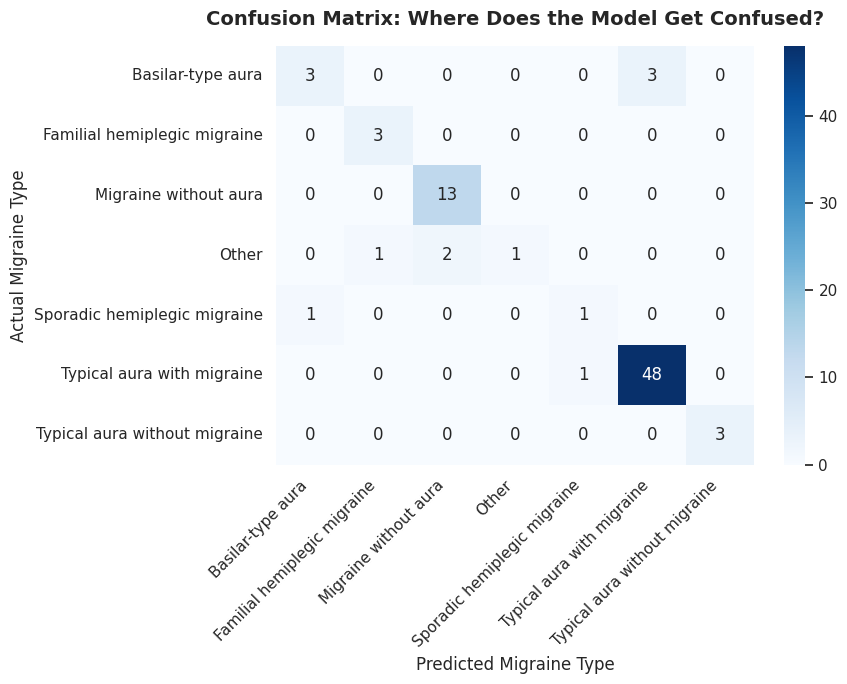

In [19]:
import xgboost as xgb
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Encode text labels to numbers (required by XGBoost)
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

# 2. Initialize and train the XGBoost Classifier
xgb_model = xgb.XGBClassifier(
    random_state=42,
    eval_metric='mlogloss',
    use_label_encoder=False
)
xgb_model.fit(X_train, y_train_encoded)

# 3. Predict and evaluate accuracy
y_pred_encoded = xgb_model.predict(X_test)
print(f"XGBoost Accuracy: {accuracy_score(y_test_encoded, y_pred_encoded):.3f}")

# 4. Plot the Confusion Matrix Heatmap
plt.figure(figsize=(9, 7))
cm = confusion_matrix(y_test_encoded, y_pred_encoded)
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=le.classes_, 
    yticklabels=le.classes_
)
plt.title("Confusion Matrix: Where Does the Model Get Confused?", fontsize=14, pad=15, fontweight='bold')
plt.xlabel("Predicted Migraine Type", fontsize=12)
plt.ylabel("Actual Migraine Type", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Project Summary & Key Learnings**


Data-Driven Realities: The exploratory analysis successfully mapped out the non-linear complexity of neurological pain, confirming that clinical features like age, duration, and intensity operate independently rather than scaling linearly.

Predictive Capability: By deploying both Random Forest and XGBoost classifiers, we demonstrated that patient profiles and symptoms can predict specific migraine classifications with high accuracy (~93%), though model performance heavily reflects real-world data distribution across rare subtypes.